# Handwritten Digit Recognition (MNIST)

## Project Description
This project focuses on classifying handwritten digits (0-9) using the MNIST dataset.
The following experiments were conducted as part of the project:
- Convolutional Neural Network (CNN) built with Keras/TensorFlow without data augmentation (Branch 1)
- Convolutional Neural Network (CNN) built with Keras/TensorFlow with data augmentation (Branch 2)
- Custom CNN implementation written from scratch in NumPy (Branch 3)

### Authors
- Bartosz Majewski

### Technologies
- Python 3.13
- TensorFlow / Keras
- NumPy, Pandas, Matplotlib, Seaborn
- scikit-learn
- Custom `my_cnn` library (CNN implementation from scratch)

---
# 1. Training Set Analysis

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models, losses
from tensorflow.keras.datasets import mnist
from sklearn.metrics import classification_report, confusion_matrix

sns.set_theme(style='whitegrid')
%matplotlib inline

# fixed seed so the results can be reproduced
SEED = 42
np.random.seed(SEED)

In [2]:
# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Basic information about the MNIST dataset")
print(f"Training set:  {x_train.shape[0]:>10,} images")
print(f"Test set:     {x_test.shape[0]:>10,} images")
print(f"Total count:     {x_train.shape[0] + x_test.shape[0]:>10,} images")
print(f"\nImage dimensions:    {x_train.shape[1]} x {x_train.shape[2]} pixels (grayscale)")
print(f"Number of features (pixels): {x_train.shape[1] * x_train.shape[2]}")
print(f"Pixel value range: [{x_train.min()}, {x_train.max()}]")
print(f"Data type: {x_train.dtype}")
print(f"Number of classes: {len(np.unique(y_train))} (digits 0-9)")

Basic information about the MNIST dataset
Training set:      60,000 images
Test set:         10,000 images
Total count:         70,000 images

Image dimensions:    28 x 28 pixels (grayscale)
Number of features (pixels): 784
Pixel value range: [0, 255]
Data type: uint8
Number of classes: 10 (digits 0-9)


### 1.1 Class Distribution (Dataset Balance)

In [3]:
# Class distribution in the training set
unique_train, counts_train = np.unique(y_train, return_counts=True)
unique_test, counts_test = np.unique(y_test, return_counts=True)

df_balance = pd.DataFrame({
    'Digit': unique_train,
    'Training (n)': counts_train,
    'Training (%)': np.round(counts_train / len(y_train) * 100, 2),
    'Test (n)': counts_test,
    'Test (%)': np.round(counts_test / len(y_test) * 100, 2),
})
print("Class distribution:")
display(df_balance)

print(f"\nMax/min ratio in the training set: {counts_train.max() / counts_train.min():.2f}")
print(f"Standard deviation of percentage share: {np.std(counts_train / len(y_train) * 100):.2f}%")

Class distribution:

Max/min ratio in the training set: 1.24
Standard deviation of percentage share: 0.54%


,Digit,Training (n),Training (%),Test (n),Test (%)
0,0,5923,9.87,980,9.80
1,1,6742,11.24,1135,11.35
2,2,5958,9.93,1032,10.32
3,3,6131,10.22,1010,10.10
4,4,5842,9.74,982,9.82
5,5,5421,9.04,892,8.92
6,6,5918,9.86,958,9.58
7,7,6265,10.44,1028,10.28
8,8,5851,9.75,974,9.74
9,9,5949,9.92,1009,10.09


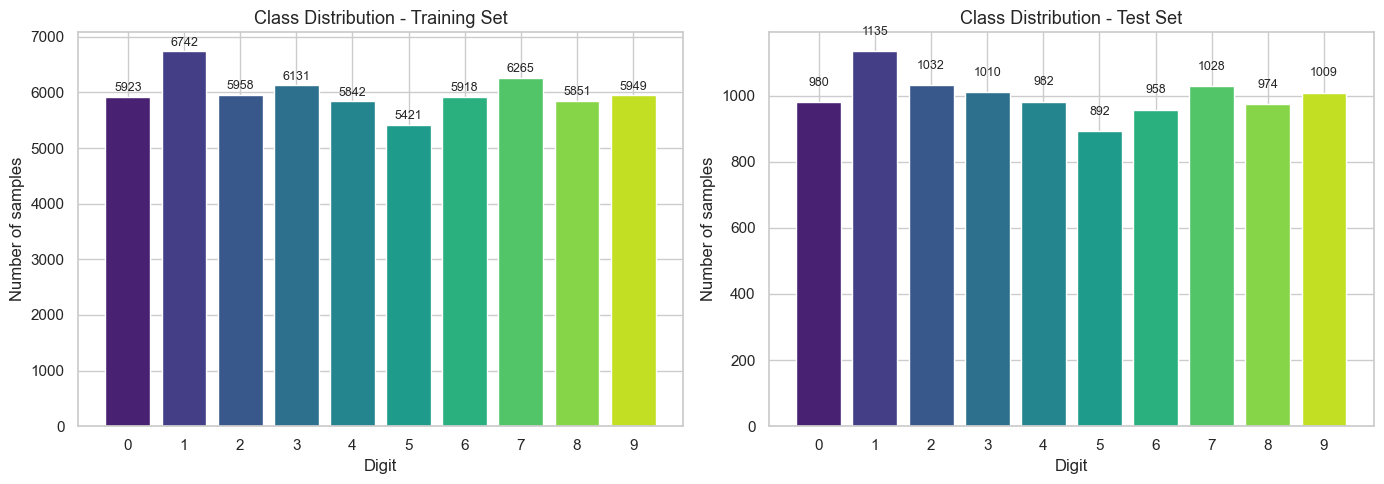

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette('viridis', 10)

axes[0].bar(unique_train, counts_train, color=colors)
axes[0].set_title('Class Distribution - Training Set', fontsize=13)
axes[0].set_xlabel('Digit')
axes[0].set_ylabel('Number of samples')
axes[0].set_xticks(range(10))
for i, v in enumerate(counts_train):
    axes[0].text(i, v + 100, str(v), ha='center', fontsize=9)

axes[1].bar(unique_test, counts_test, color=colors)
axes[1].set_title('Class Distribution - Test Set', fontsize=13)
axes[1].set_xlabel('Digit')
axes[1].set_ylabel('Number of samples')
axes[1].set_xticks(range(10))
for i, v in enumerate(counts_test):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 1.2 Sample Images from Dataset

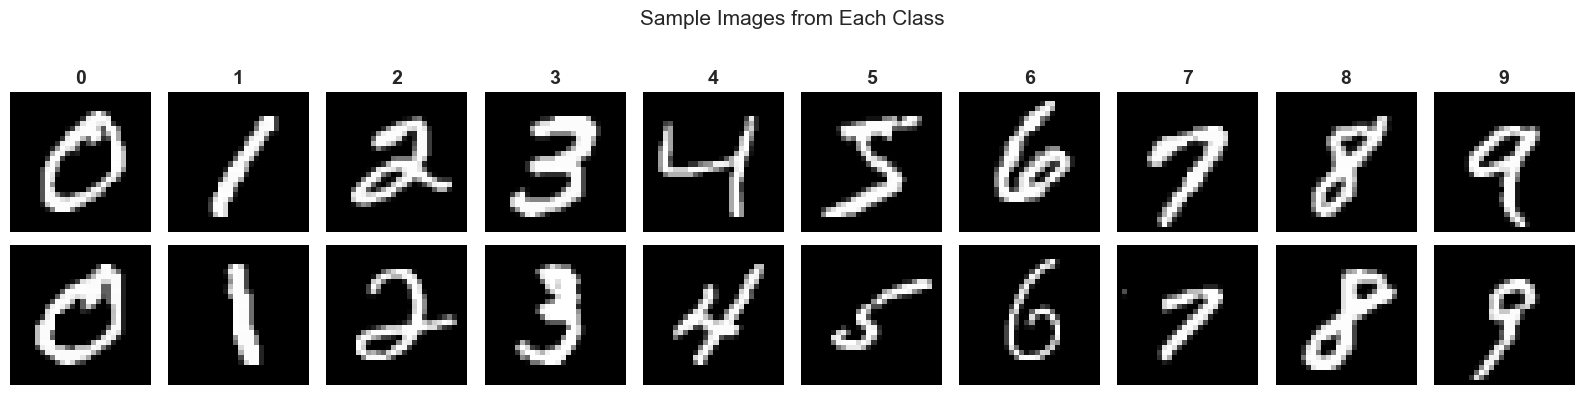

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for digit in range(10):
    idxs = np.where(y_train == digit)[0]
    for row in range(2):
        ax = axes[row, digit]
        ax.imshow(x_train[idxs[row]], cmap='gray')
        ax.axis('off')
        if row == 0:
            ax.set_title(str(digit), fontsize=14, fontweight='bold')
fig.suptitle('Sample Images from Each Class', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### 1.3 Pixel Statistics

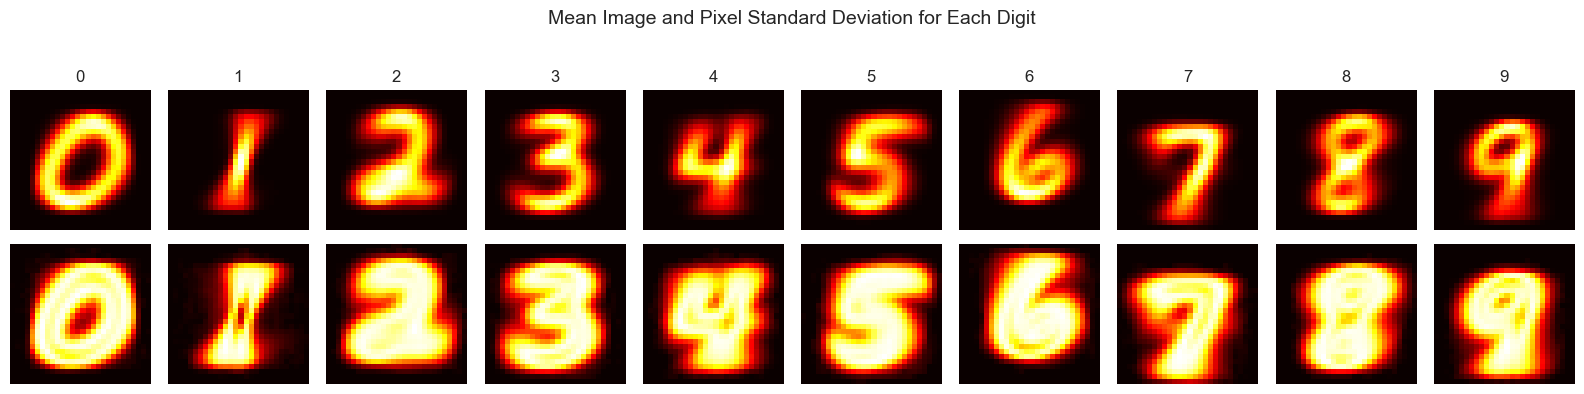

In [6]:
# Mean image and pixel standard deviation
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for digit in range(10):
    digit_imgs = x_train[y_train == digit]
    mean_img = digit_imgs.mean(axis=0)
    std_img = digit_imgs.std(axis=0)
    
    axes[0, digit].imshow(mean_img, cmap='hot')
    axes[0, digit].axis('off')
    axes[0, digit].set_title(str(digit), fontsize=12)
    
    axes[1, digit].imshow(std_img, cmap='hot')
    axes[1, digit].axis('off')

axes[0, 0].set_ylabel('Mean', fontsize=11)
axes[1, 0].set_ylabel('Std. Dev.', fontsize=11)
fig.suptitle('Mean Image and Pixel Standard Deviation for Each Digit', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

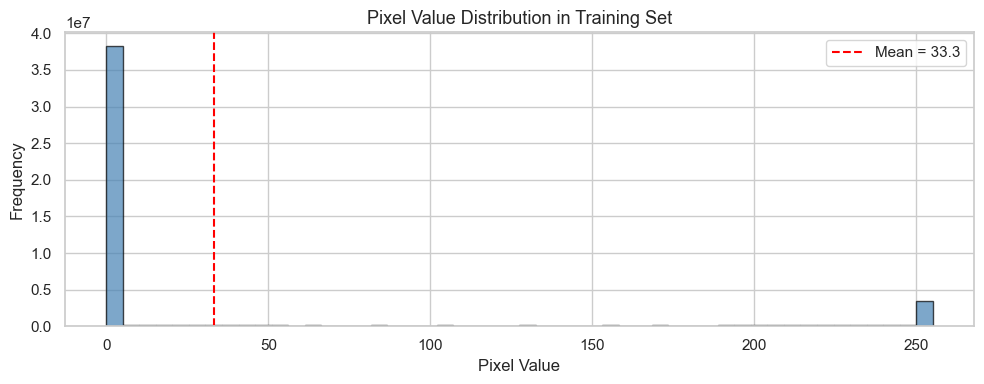

Percentage of non-zero pixels: 19.1%
Percentage of zero pixels (background): 80.9%


In [7]:
# Pixel value distribution in training set
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.hist(x_train.flatten(), bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_title('Pixel Value Distribution in Training Set', fontsize=13)
ax.set_xlabel('Pixel Value')
ax.set_ylabel('Frequency')
ax.axvline(x=x_train.flatten().mean(), color='red', linestyle='--', label=f'Mean = {x_train.flatten().mean():.1f}')
ax.legend()
plt.tight_layout()
plt.show()

nonzero_pct = (x_train > 0).sum() / x_train.size * 100
print(f"Percentage of non-zero pixels: {nonzero_pct:.1f}%")
print(f"Percentage of zero pixels (background): {100 - nonzero_pct:.1f}%")

---
# 2. Feature (Pixel) Importance Analysis

In the case of images, pixels represent the input features of the model. Instead of classic feature selection methods (like SelectKBest), which assume tabular features, we use an approach based on pixel variance analysis.

### Method: Inter-class Pixel Variance Analysis
We calculate the mean image for each class, and then the variance of these mean images across classes.
Pixels with high inter-class variance are those that differentiate the digits the most – making them the most significant features.
Pixels with low variance (e.g., corners of the image) convey little to no information for classification.

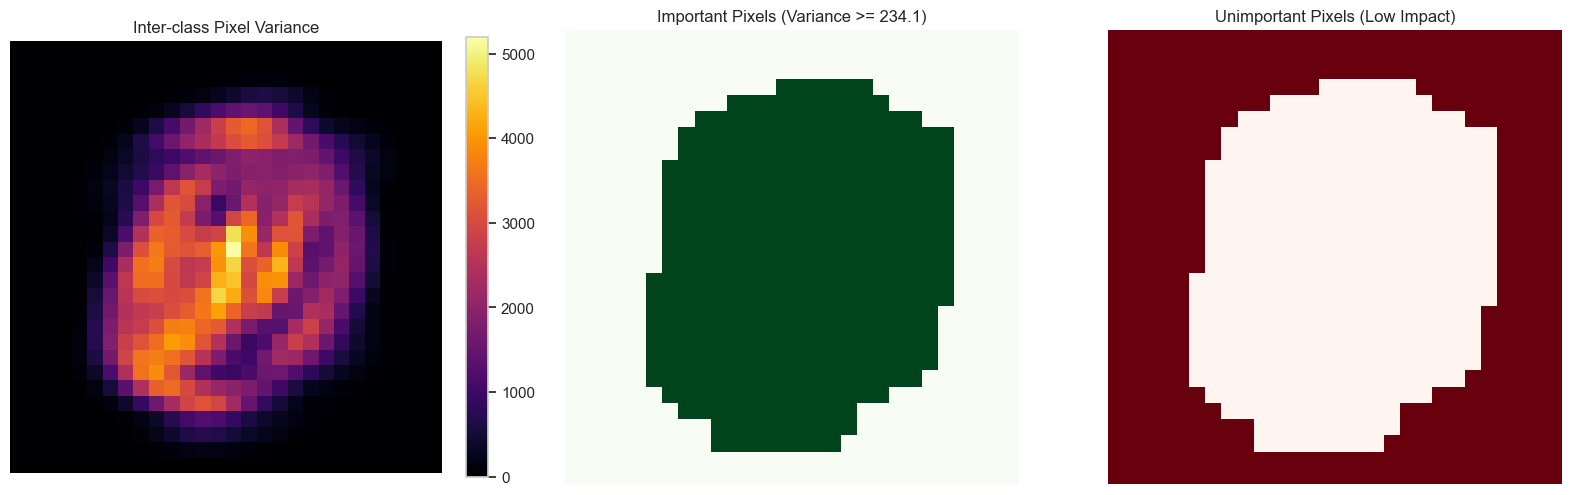

Number of important pixels: 359 / 784 (45.8%)
Number of unimportant pixels: 425 / 784 (54.2%)


In [8]:
# Compute mean images for each class
class_means = np.array([x_train[y_train == d].mean(axis=0) for d in range(10)])

# Inter-class variance - calculate variance across the 10 means for each pixel
inter_class_variance = class_means.var(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Variance map
im0 = axes[0].imshow(inter_class_variance, cmap='inferno')
axes[0].set_title('Inter-class Pixel Variance', fontsize=12)
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# Mask: pixels above median variance
threshold = np.median(inter_class_variance[inter_class_variance > 0])
important_mask = (inter_class_variance >= threshold).astype(float)
axes[1].imshow(important_mask, cmap='Greens')
axes[1].set_title(f'Important Pixels (Variance >= {threshold:.1f})', fontsize=12)
axes[1].axis('off')

# Unimportant pixels (corners, edges)
unimportant_mask = (inter_class_variance < threshold).astype(float)
axes[2].imshow(unimportant_mask, cmap='Reds')
axes[2].set_title('Unimportant Pixels (Low Impact)', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

n_important = int(important_mask.sum())
n_total = 28 * 28
print(f"Number of important pixels: {n_important} / {n_total} ({n_important/n_total*100:.1f}%)")
print(f"Number of unimportant pixels: {n_total - n_important} / {n_total} ({(n_total - n_important)/n_total*100:.1f}%)")

In [9]:
# Pixel ranking by inter-class variance
variance_flat = inter_class_variance.flatten()
pixel_ranking = np.argsort(variance_flat)[::-1]

top_n = 20
print(f"Top {top_n} most important pixels (index, position row x column, variance):")
print("-" * 55)
for rank, idx in enumerate(pixel_ranking[:top_n], 1):
    row, col = divmod(idx, 28)
    print(f"  {rank:>2}. Pixel [{row:>2}, {col:>2}]  (index {idx:>3})  variance = {variance_flat[idx]:.2f}")

Top 20 most important pixels (index, position row x column, variance):
-------------------------------------------------------
   1. Pixel [13, 14]  (index 378)  variance = 5200.81
   2. Pixel [12, 14]  (index 350)  variance = 4776.06
   3. Pixel [16, 13]  (index 461)  variance = 4678.83
   4. Pixel [14, 14]  (index 406)  variance = 4660.99
   5. Pixel [15, 14]  (index 434)  variance = 4488.41
   6. Pixel [14, 17]  (index 409)  variance = 4331.34
   7. Pixel [15, 13]  (index 433)  variance = 4298.57
   8. Pixel [16, 14]  (index 462)  variance = 4229.58
   9. Pixel [17, 13]  (index 489)  variance = 4122.39
  10. Pixel [19, 10]  (index 542)  variance = 4047.98
  11. Pixel [13, 13]  (index 377)  variance = 4020.39
  12. Pixel [15, 17]  (index 437)  variance = 3946.40
  13. Pixel [14, 13]  (index 405)  variance = 3923.16
  14. Pixel [19, 11]  (index 543)  variance = 3920.60
  15. Pixel [15, 16]  (index 436)  variance = 3911.72
  16. Pixel [12, 15]  (index 351)  variance = 3902.98
  17. Pix

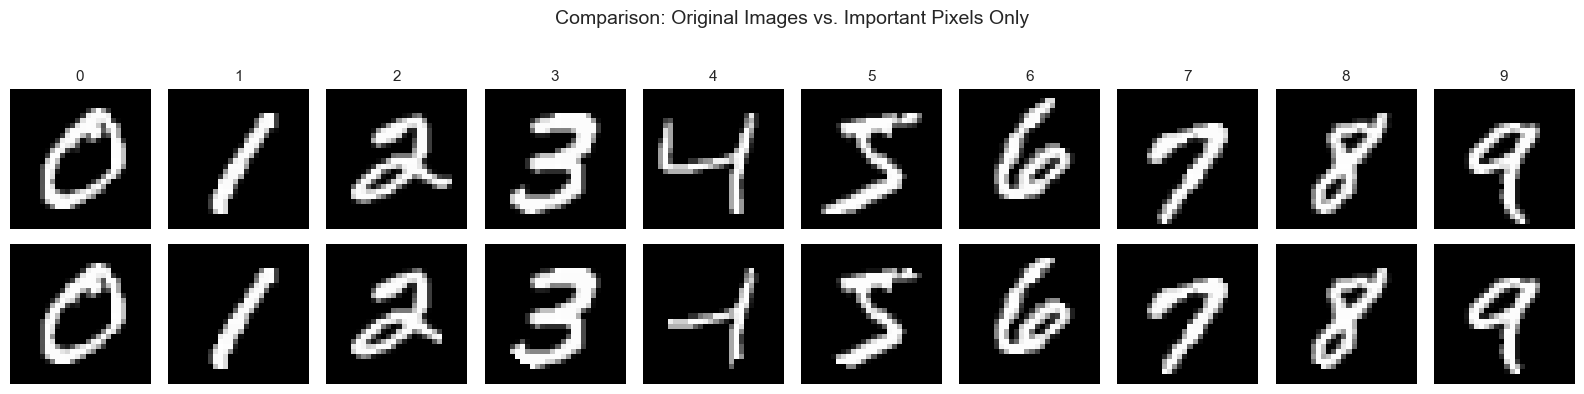

In [10]:
# Visualization: effect of removing unimportant pixels
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    original = x_train[idx]
    masked = original * important_mask
    
    axes[0, digit].imshow(original, cmap='gray')
    axes[0, digit].axis('off')
    axes[0, digit].set_title(str(digit), fontsize=11)
    
    axes[1, digit].imshow(masked, cmap='gray')
    axes[1, digit].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=11)
axes[1, 0].set_ylabel('After Mask', fontsize=11)
fig.suptitle('Comparison: Original Images vs. Important Pixels Only', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
# 3. Data Augmentation

To make the model robust against handwriting imperfections and increase overall network generalization capability, two forms of training data augmentation were introduced:
1. **Rotation**: Each image is rotated by angles ranging from -20° to 20° with a step of 5°.
2. **Gaussian Noise**: Gaussian noise from a normal distribution (std=20) is added to the images (both original and rotated), simulating scanning noise or background artifacts.

The applied logic generates new samples for each input image:
- Adding Gaussian noise to the original.
- Generating rotated variants.
- Adding noise to the generated rotated variants.

In total for each image: 1 (original) + 1 (noise) + 8 (rotations) + 8 (rotations+noise) = 18 variants.

Total: 54,000 x 18 = 972,000 records. Augmentation is applied only to the training part, after 6,000 images have been set aside for validation, so no rotated or noisy copy of a validation image ends up in the training set.

This augmentation is used in Branch 2. Branch 3 (custom CNN) uses a lighter variant, described in section 4.3.

### 3.1 Augmentation Examples for Each Digit

The visualization below shows sample modifications for each digit (0-9) from the dataset. We present in sequence:
1. Original image
2. Image rotated by 20 degrees
3. Image with added Gaussian noise (std=20)
4. Combination of both transformations (20-degree rotation + noise)

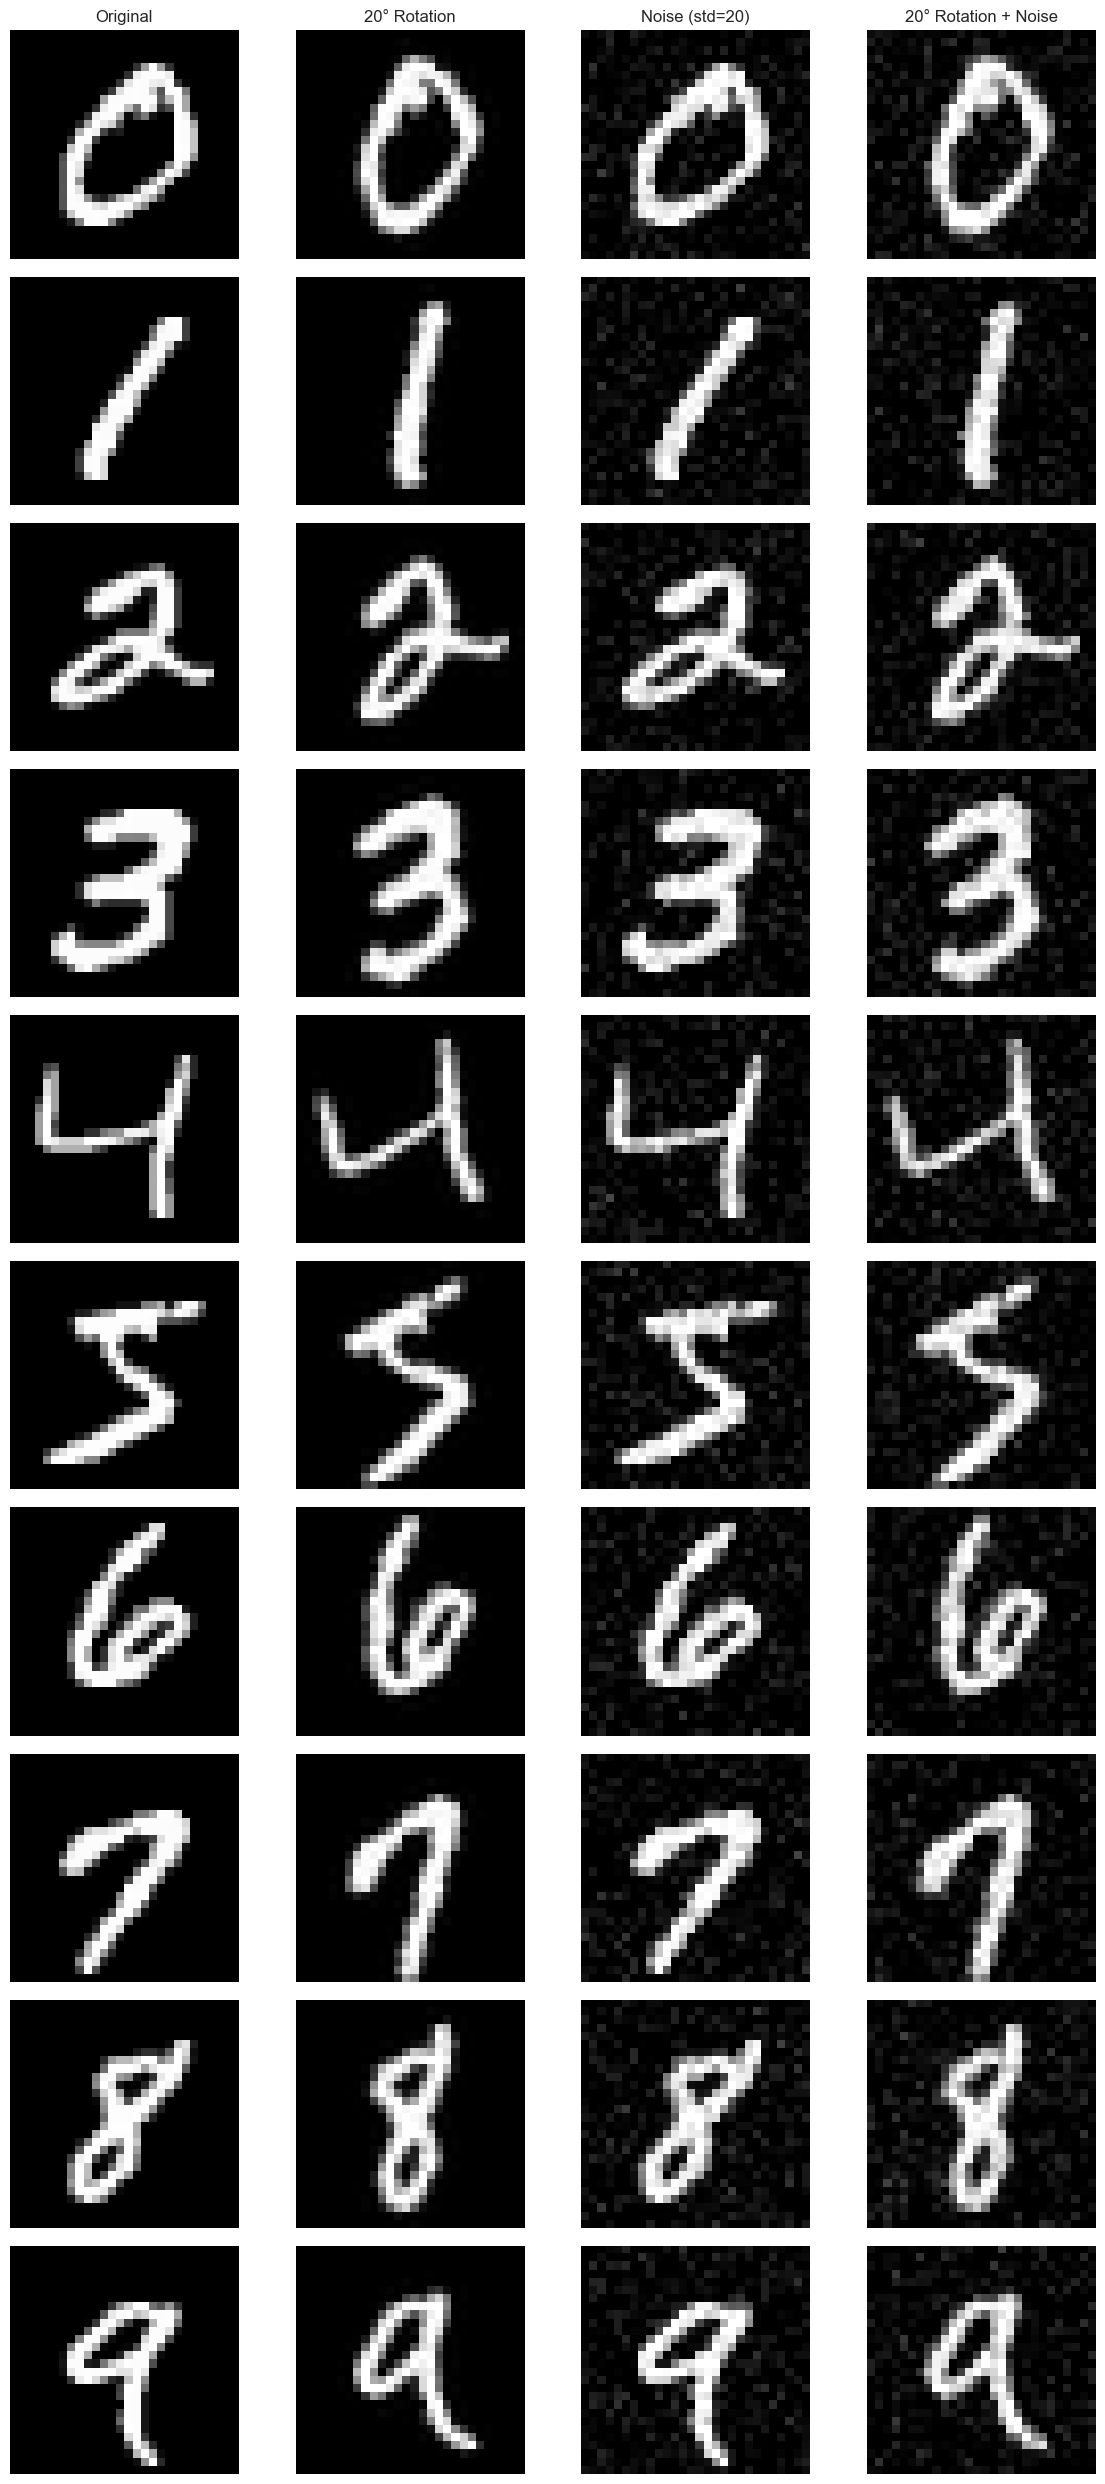

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import rotate

# Transformation visualization examples
NOISE_STD = 20.0

fig, axes = plt.subplots(10, 4, figsize=(12, 25))

samples = [x_train[y_train == i][0] for i in range(10)]

for i, img in enumerate(samples):
    # 1. Original
    axes[i, 0].imshow(img, cmap='gray')
    if i == 0:
        axes[i, 0].set_title("Original")
    axes[i, 0].axis('off')
    
    # 2. Rotation
    img_rot = rotate(img, 20, axes=(0,1), reshape=False, mode='constant', cval=0.0)
    axes[i, 1].imshow(img_rot, cmap='gray')
    if i == 0:
        axes[i, 1].set_title("20° Rotation")
    axes[i, 1].axis('off')
    
    # 3. Noise
    noise = np.random.normal(loc=0.0, scale=NOISE_STD, size=img.shape)
    img_noised = img + noise
    img_noised = np.clip(img_noised, 0, 255).astype(np.uint8)
    axes[i, 2].imshow(img_noised, cmap='gray')
    if i == 0:
        axes[i, 2].set_title(f"Noise (std={int(NOISE_STD)})")
    axes[i, 2].axis('off')
    
    # 4. Rotation + Noise
    noise_rot = np.random.normal(loc=0.0, scale=NOISE_STD, size=img_rot.shape)
    img_rot_noised = img_rot + noise_rot
    img_rot_noised = np.clip(img_rot_noised, 0, 255).astype(np.uint8)
    axes[i, 3].imshow(img_rot_noised, cmap='gray')
    if i == 0:
        axes[i, 3].set_title("20° Rotation + Noise")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

---
# 4. Experiments

The 3 experiment branches are presented below.

**Data split (identical in every branch):** the 60,000 MNIST training images are split (stratified, `random_state=42`) into 54,000 training and 6,000 validation images. The validation set is used to monitor training, and the 10,000-image test set is used only once, for the final evaluation. Every notebook sets a fixed seed (`SEED = 42`), so the results can be reproduced.

**Evaluation Metrics:**
- **Accuracy** - overall classification accuracy
- **Precision** - macro-averaged precision across classes
- **Recall** - macro-averaged recall across classes
- **F1-score** - harmonic mean of precision and recall

## 4.1 Branch 1 - Keras CNN without Augmentation

Training set: **54,000 images** (original MNIST, without augmentation) + 6,000 validation images.

Training code: `notebooks/recognition_without_augmentation.ipynb`

## 4.2 Branch 2 - Keras CNN with Data Augmentation

Training set: **972,000 images** (54,000 MNIST images x 18 variants: rotations + Gaussian noise, see section 3) + 6,000 validation images (not augmented).

Training code: `notebooks/recognition_with_augmentation.ipynb`

## 4.3 Branch 3 - Custom CNN Implementation (my_cnn)

Network written from scratch in NumPy with custom implementation of:
- Layers: `Convolution2D`, `MaxPooling2D`, `Dense`, `Flatten`, `Rescaling`, `Input`
- Activation functions: `ReLU`, `Softmax`
- Loss function: `CrossEntropy`
- Optimizers: `SGD`, `Momentum` (SGD with momentum, β = 0.9). The model is trained with `Momentum`, learning rate 0.02.

Training set: **162,000 images** (54,000 MNIST images x 3 variants: rotations by -12°, 0° and +12°) + 6,000 validation images (not augmented).

Training code: `notebooks/mycnn.ipynb`

# 5. Comparison of Results Across Branches

Final results of each branch. Loss and accuracy are measured on the test set (10,000 images, not used during training).
<table border="1">
  <thead>
    <tr>
      <th></th>
      <th>Test loss</th>
      <th>Test accuracy (%)</th>
      <th>Validation accuracy (%)</th>
      <th>Precision (macro avg)</th>
      <th>Recall (macro avg)</th>
      <th>F1-score (macro avg)</th>
      <th>Training images</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Without augmentation</td>
      <td>0.0524</td>
      <td>98.26</td>
      <td>98.15</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>54,000</td>
    </tr>
    <tr>
      <td>With augmentation</td>
      <td>0.0213</td>
      <td>99.36</td>
      <td>98.97</td>
      <td>0.99</td>
      <td>0.99</td>
      <td>0.99</td>
      <td>972,000</td>
    </tr>
    <tr>
      <td>Custom CNN</td>
      <td>0.0332</td>
      <td>98.94</td>
      <td>98.58</td>
      <td>0.99</td>
      <td>0.99</td>
      <td>0.99</td>
      <td>162,000</td>
    </tr>
  </tbody>
</table>

**Note: the three models are not trained under identical conditions**, so the table shows how each setup performs, not which implementation is better. Differences:

| | Branch 1: Keras | Branch 2: Keras + augmentation | Branch 3: custom CNN (NumPy) |
| :--- | :---: | :---: | :---: |
| Convolution padding | `valid` (28→26→13→11→5) | `valid` (28→26→13→11→5) | `same` (28→28→14→14→7) |
| Dropout | 0.3 | 0.3 | none |
| Trainable parameters | 121,930 | 121,930 | 220,234 |
| Optimizer | Adam (lr 0.001) | Adam (lr 0.001) | SGD + momentum (lr 0.02, β 0.9) |
| Batch size | 32 | 64 | 128 |
| Epochs | 2 | 1 | 2 |
| Training images | 54,000 | 972,000 (x18) | 162,000 (x3) |
| Augmentation | none | rotations -20°…+20° (step 5°) + Gaussian noise | rotations -12°, 0°, +12° |

The validation set (6,000 images) and the test set (10,000 images) are the same for all three models.

---
# 6. Observations (Results Interpretation)

## 6.1 How did data augmentation affect the results?
Augmentation improved the results. Expanding the training set (through rotations and noise) from 54,000 to 972,000 images raised test accuracy from 98.26% to 99.36% and lowered test loss from 0.0524 to 0.0213. Augmentation causes the network to learn to ignore insignificant variations in handwriting (e.g., writing angle) and thus makes fewer errors on new test data.

Part of the gain may also come from longer training: one epoch over 972,000 images means about 15,000 weight updates, compared with about 3,400 for two epochs over 54,000 images.

## 6.2 How does the custom CNN implementation compare to Keras?
The custom implementation in pure NumPy reaches 98.94% test accuracy, between the two Keras models (98.26% and 99.36%). This confirms that the forward pass and backpropagation in `my_cnn` work correctly. Because the setups differ (see the note under the table in section 5), this should not be read as one implementation being better than the other. Keras offers faster development and optimized operations (e.g., the Adam optimizer out of the box), while the NumPy version shows exactly how every layer and gradient is computed.

## 6.3 Which digits are most frequently confused?
The most frequently confused digits are those that inherently have very similar visual patterns, especially in sloppy handwriting. Commonly confused pairs in the MNIST dataset include 4 and 9, 3 and 5 (similar curves) and 7 and 9. Digits 2 and 7 are also frequently confused. This is due to the fact that sometimes classification is determined by a single sequence of pixels (or lack thereof) connecting the lines of the digit.

---
# 7. Final Conclusions
- **CNN Effectiveness:** Convolutional architectures excel at image classification and digit recognition, demonstrating precision close to 100% on the MNIST dataset.
- **Robustness and Regularization:** Mechanisms such as Dropout are essential for complex networks, facilitating proper learning rather than mere memorization of the training set.
- **Power of Augmentation:** Manipulating input data through artificial dataset expansion teaches the model greater tolerance for human handwriting errors (rotations, blurring), resulting in significantly higher accuracy during testing.
- **Keras vs. From Scratch:** Ready-made and optimized deep learning solutions (Keras) allow constructing and training a powerful classifier in a fraction of the time. On the other hand, writing a network from scratch (NumPy) allows for a deep understanding of the mathematical aspects and mechanics of deep neural networks.